# 01 · Preparación de datos y modelo ingenuo (ENUT 2024)

**Pregunta:** entre mujeres de 25 a 54 años, ¿qué características del hogar se asocian con estar fuera del mercado laboral?

**Decisión que informa:** a qué tipo de hogar debería dirigirse un programa de cuidados (por ejemplo, hogares con niñas y niños pequeños o con personas que requieren cuidados).

**Qué hace este notebook**

1. Carga los datos abiertos de la ENUT 2024 (INEGI).
2. Revisa la calidad de los datos y corrige un problema real en las llaves.
3. Construye variables de composición del hogar.
4. Arma la base analítica de mujeres de 25 a 54 años.
5. Ajusta una regresión logística **ignorando el diseño muestral** (el "modelo ingenuo") y la compara con una aproximación que sí considera los conglomerados.
6. Prueba si la asociación cambia según la escolaridad (interacción).
7. Valida la calibración del modelo y su robustez ante cambios en las decisiones del análisis.
8. Exporta la base para el notebook 02 (R, con el paquete `survey`).

**Lo que este notebook no hace:** estimar efectos causales. Todo lo que sigue son asociaciones.

## 1. Configuración
Antes de correr este notebook ejecuta `python scripts/descargar_enut.py` desde la raíz del repo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import warnings

# statsmodels avisa que cov_type="cluster" con pesos "no está totalmente soportado".
# En la sección 7 verificamos a mano que los errores estándar son correctos.
warnings.filterwarnings("ignore", message="cov_type not fully supported")

# Paleta validada para daltonismo (azul/naranja = sin/con menores de 6 años)
COL = {"sin": "#2a78d6", "con": "#eb6834", "domestico": "#1baf7a", "cuidados": "#6250d6", "tinta": "#3a3a38", "gris": "#9a9a95"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e4e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": "#9a9a95", "xtick.color": "#3a3a38", "ytick.color": "#3a3a38",
})

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "data" / "raw" / "enut_2024"
PROCESSED = RAIZ / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
assert RAW.exists(), "No encuentro data/raw/enut_2024. Corre primero scripts/descargar_enut.py"


def cargar_tabla(nombre: str) -> pd.DataFrame:
    # Todas las columnas como texto: así no se pierden ceros a la izquierda
    # en claves como est_dis (0001) o upm_dis (00019).
    ruta = next((RAW / f"conjunto_de_datos_tr_enut24_{nombre}_enut_2024" / "conjunto_de_datos").glob("*.csv"))
    return pd.read_csv(ruta, dtype=str, low_memory=False)


def diccionario(nombre: str) -> pd.DataFrame:
    ruta = next((RAW / f"conjunto_de_datos_tr_enut24_{nombre}_enut_2024" / "diccionario_de_datos").glob("*.csv"))
    return pd.read_csv(ruta)

## 2. Carga de tablas

| Tabla | Unidad | Para qué la usamos |
|---|---|---|
| `tvar_crea` | Persona elegida de 12+ años | Variables creadas por INEGI: horas por actividad, condición de actividad (`cond_aee`), escolaridad, factor `fac_per`, estrato y UPM |
| `tsdem` | Todos los residentes del hogar | Composición del hogar: edades, parentesco, necesidad de cuidados, asistencia a guardería |

In [2]:
vc = cargar_tabla("tvar_crea")
sd = cargar_tabla("tsdem")
print("tvar_crea:", vc.shape, "| tsdem:", sd.shape)

tvar_crea: (74053, 60) | tsdem: (94565, 33)


In [3]:
# Las variables que vamos a usar, según el diccionario oficial
dic = diccionario("tvar_crea")
dic[dic["nemónico"].isin(["cond_aee", "trab_no_rem_cuid_hog", "escolaridad", "fac_per", "est_dis", "upm_dis"])][["nemónico", "nombre_campo"]]

,nemónico,nombre_campo
20,trab_no_rem_cuid_hog,Trabajo no remunerado de cuidado a integrantes...
49,escolaridad,Escolaridad
52,cond_aee,Condición de actividad económica específica
53,est_dis,Estrato de diseño muestral
54,upm_dis,Unidad primaria de muestreo
55,fac_per,Factor


## 3. Control de calidad

### 3.1 Las llaves de persona vienen corruptas
Lo esperable es que `llavemod` (en `tvar_crea`) y `llavesde` (en `tsdem`) identifiquen a cada persona de forma única. Revisamos:

In [4]:
for nombre, df, llave in [("tvar_crea", vc, "llavemod"), ("tsdem", sd, "llavesde")]:
    print(f"{nombre}.{llave}: única = {df[llave].is_unique}; longitudes = {df[llave].str.len().value_counts().to_dict()}")

vc.loc[vc["llavemod"].str.contains("E", na=False), ["llavemod", "llavehog", "n_ren"]].head()

tvar_crea.llavemod: única = False; longitudes = {11: 49289, 12: 20103, 10: 4127, 9: 481, 8: 53}
tsdem.llavesde: única = False; longitudes = {11: 63183, 12: 25445, 10: 5299, 9: 571, 8: 67}


,llavemod,llavehog,n_ren
19688,1.00224E+11,1002241051,03
19689,1.00224E+11,1002241051,04
19690,1.00226E+11,1002257011,01
19691,1.00226E+11,1002257021,01
19692,1.00263E+11,1002632011,01


**Hallazgo.** Parte de las llaves de 12 dígitos vienen en notación científica (`1.00006E+11`): alguien abrió el archivo en Excel antes de publicarlo. Si uniéramos las tablas por esas llaves, emparejaríamos personas equivocadas sin ver ningún error.

**Corrección.** La llave de persona es la llave del hogar (10 dígitos, que sí viene bien) más el número de renglón (`n_ren`). La reconstruimos y comprobamos que sea única.

In [5]:
for df in (vc, sd):
    assert df["llavehog"].str.len().eq(10).all() and df["n_ren"].str.len().eq(2).all()
    df["id_persona"] = df["llavehog"] + df["n_ren"]

assert vc["id_persona"].is_unique and sd["id_persona"].is_unique
assert vc["id_persona"].isin(sd["id_persona"]).all(), "Hay personas elegidas que no aparecen en tsdem"
print("Llaves reconstruidas: únicas y consistentes entre tablas.")

Llaves reconstruidas: únicas y consistentes entre tablas.


### 3.2 Tipos y prueba de cordura con el factor de expansión
Convertimos a número lo que es número. La suma de `fac_per` debe aproximar a la población de 12 años y más de México (alrededor de 105 a 110 millones).

In [6]:
horas_cols = [c for c in dic["nemónico"] if c.startswith(("activ_", "trab_", "cuid_", "prep_", "limp_", "mant_", "compras", "pagos", "org_", "tras_", "bus_", "prod_", "apoy_"))]
vc[horas_cols] = vc[horas_cols].apply(pd.to_numeric)
vc[["edad", "fac_per"]] = vc[["edad", "fac_per"]].apply(pd.to_numeric)
sd["edad"] = pd.to_numeric(sd["edad"], errors="coerce")

print(f"Población expandida 12+: {vc['fac_per'].sum():,.0f}")
print(f"Personas en muestra: {len(vc):,} | estratos: {vc['est_dis'].nunique()} | UPM: {vc['upm_dis'].nunique():,}")
print("Nulos en variables clave:", vc[["cond_aee", "fac_per", "est_dis", "upm_dis", "edad", "sexo"]].isna().sum().sum())

Población expandida 12+: 107,829,510
Personas en muestra: 74,053 | estratos: 342 | UPM: 4,200
Nulos en variables clave: 0


## 4. Composición del hogar (desde `tsdem`)
Para cada hogar contamos a sus integrantes por grupo de edad y a quienes necesitaron cuidados la semana pasada. Estas son las variables del programa: describen la **demanda de cuidados** que enfrenta el hogar.

In [7]:
sd["req_cuidado"] = (sd["p3_7"].eq("1") | sd["p3_8"].isin(["1", "2"])).astype(int)

hogar = sd.groupby("llavehog").agg(
    n_0a5=("edad", lambda e: (e <= 5).sum()),
    n_6a14=("edad", lambda e: e.between(6, 14).sum()),
    n_60mas=("edad", lambda e: (e >= 60).sum()),
    n_req_cuidado=("req_cuidado", "sum"),
    n_residentes=("id_persona", "size"),
).reset_index()

# Asistencia a guardería o preescolar: la pregunta P3.10 solo se aplica a menores (verificado abajo)
print("Edades a las que se aplicó P3.10:", sorted(sd.loc[sd["p3_10"].notna(), "edad"].unique()))
guard = (sd[sd["p3_10"].notna()].assign(asiste=lambda d: d["p3_10"].eq("1"))
         .groupby("llavehog")["asiste"].any().rename("algun_menor_en_guarderia").reset_index())
hogar = hogar.merge(guard, on="llavehog", how="left")
hogar.describe().T

Edades a las que se aplicó P3.10: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,count,mean,std,min,25%,50%,75%,max
n_0a5,"29,181.000",0.253,0.544,0.000,0.000,0.000,0.000,5.000
n_6a14,"29,181.000",0.527,0.824,0.000,0.000,0.000,1.000,7.000
n_60mas,"29,181.000",0.471,0.724,0.000,0.000,0.000,1.000,7.000
n_req_cuidado,"29,181.000",0.167,0.466,0.000,0.000,0.000,0.000,7.000
n_residentes,"29,181.000",3.241,1.744,1.000,2.000,3.000,4.000,18.000


## 5. Base analítica: mujeres de 25 a 54 años

**Por qué 25 a 54:** es la edad laboral principal. Antes de los 25 muchas personas estudian; después de los 54 aumentan las jubilaciones. Sin este recorte, el modelo confundiría "estudia" o "se jubiló" con "cuida".

**Variable de respuesta:** `fuera_mercado = 1` si la persona no está ocupada ni desocupada (`cond_aee` distinto de 1 y 2).

In [8]:
print(pd.read_csv(RAW / "conjunto_de_datos_tr_enut24_tvar_crea_enut_2024" / "catalogos" / "cond_aee.csv").to_string(index=False))

 cve                                                              descrip
   1                                                              Ocupada
   2                                                           Desocupada
   3                                        Persona jubilada o pensionada
   4                                                           Estudiante
   5 Se dedica a los quehaceres del hogar  o al cuidado de algún familiar
   6                                             Estaba en otra situación


In [9]:
# Construimos las variables para TODAS las personas elegidas y luego marcamos el dominio.
# Así el notebook 02 puede definir el diseño muestral sobre la muestra completa (ver nota abajo).
paren = sd[["id_persona", "paren"]]
todas = (vc.merge(paren, on="id_persona", how="left", validate="one_to_one")
           .merge(hogar, on="llavehog", how="left", validate="many_to_one"))

todas["en_dominio"] = ((todas["sexo"] == "2") & todas["edad"].between(25, 54)).astype(int)
todas["fuera_mercado"] = (~todas["cond_aee"].isin(["1", "2"])).astype(int)
todas["grupo_edad"] = pd.cut(todas["edad"], [24, 34, 44, 54], labels=["25-34", "35-44", "45-54"])
todas["escolaridad"] = todas["escolaridad"].map({"1": "1 sin/basica", "2": "1 sin/basica", "3": "2 media sup", "4": "3 superior", "5": "3 superior"})
todas["rol_hogar"] = todas["paren"].map({"1": "jefa", "2": "conyuge"}).fillna("otro")
todas["localidad"] = todas["tloc"].map({"1": "1 urbana 100k+", "2": "2 urbana 15k-100k", "3": "3 semiurbana", "4": "4 rural"})
todas["hay_0a5"] = (todas["n_0a5"] > 0).astype(int)
todas["horas_cuidado"] = todas["trab_no_rem_cuid_hog"]   # horas semanales de cuidado a integrantes del hogar

base = todas[todas["en_dominio"] == 1].copy()
print(f"Mujeres 25-54 en muestra: {len(base):,} | población que representan: {base['fac_per'].sum():,.0f}")
print("Nulos tras los cruces:", base[["paren", "n_0a5", "escolaridad"]].isna().sum().to_dict())

Mujeres 25-54 en muestra: 20,203 | población que representan: 28,759,104
Nulos tras los cruces: {'paren': 0, 'n_0a5': 0, 'escolaridad': 0}


**Nota metodológica (estimación por dominio).** Las mujeres de 25 a 54 años son un *dominio*, no toda la muestra. Si filtras los datos antes de declarar el diseño, R pierde los estratos y UPM donde no hay mujeres de ese grupo, y la varianza se calcula mal. Lo correcto es declarar el diseño con todas las personas y después usar `subset()` sobre el diseño. Por eso exportamos la base completa con la bandera `en_dominio`.

## 6. Descriptivos ponderados
Todas las proporciones usan `fac_per`. Sin el factor, describes a la muestra, no a la población.

In [10]:
def prop_ic(g, y="fuera_mercado"):
    # Proporción ponderada con IC 95%. La varianza se calcula por linealización,
    # agregando los residuos por UPM (misma lógica que el modelo C de la sección 7).
    w, yv = g["fac_per"].to_numpy(), g[y].to_numpy()
    p = np.average(yv, weights=w)
    tot = pd.Series(w * (yv - p) / w.sum()).groupby(g["upm_dis"].to_numpy()).sum().to_numpy()
    G = len(tot)
    se = np.sqrt(G / (G - 1) * np.sum(tot ** 2)) if G > 1 else np.nan
    return pd.Series({"pct": 100 * p, "ic_inf": 100 * (p - 1.96 * se), "ic_sup": 100 * (p + 1.96 * se), "n_muestra": len(g)})

base["n_0a5_cat"] = base["n_0a5"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
t1 = base.groupby("n_0a5_cat").apply(prop_ic, include_groups=False)
t1

,pct,ic_inf,ic_sup,n_muestra
n_0a5_cat,,,,
0,30.860,29.570,32.151,"14,406.000"
1,43.415,41.309,45.521,"4,568.000"
2+,49.188,44.776,53.600,"1,229.000"


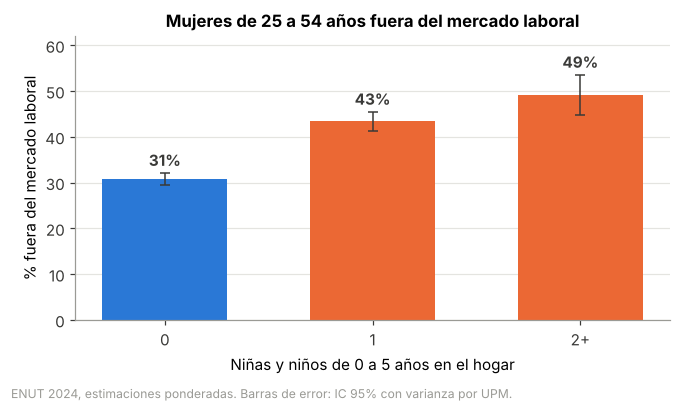

In [11]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
colores = [COL["sin"], COL["con"], COL["con"]]
ax.bar(t1.index, t1["pct"], width=0.6, color=colores)
ax.errorbar(t1.index, t1["pct"], yerr=[t1["pct"] - t1["ic_inf"], t1["ic_sup"] - t1["pct"]],
            fmt="none", ecolor=COL["tinta"], lw=1, capsize=3)
for i, (v, hi) in enumerate(zip(t1["pct"], t1["ic_sup"])):
    ax.text(i, hi + 1.5, f"{v:.0f}%", ha="center", color=COL["tinta"], fontweight="bold")
ax.set_xlabel("Niñas y niños de 0 a 5 años en el hogar")
ax.set_ylabel("% fuera del mercado laboral")
ax.set_ylim(0, 62)
ax.set_title("Mujeres de 25 a 54 años fuera del mercado laboral")
fig.text(0.01, -0.02, "ENUT 2024, estimaciones ponderadas. Barras de error: IC 95% con varianza por UPM.", fontsize=8, color=COL["gris"])
plt.tight_layout(); plt.show()

### 6.1 ¿La brecha es igual para todas?
La misma comparación, separada por escolaridad, tamaño de localidad y edad. Si la brecha entre las barras azules y naranjas cambia mucho entre grupos, un programa único no le sirve a todas por igual. La sección 8 lo prueba formalmente.

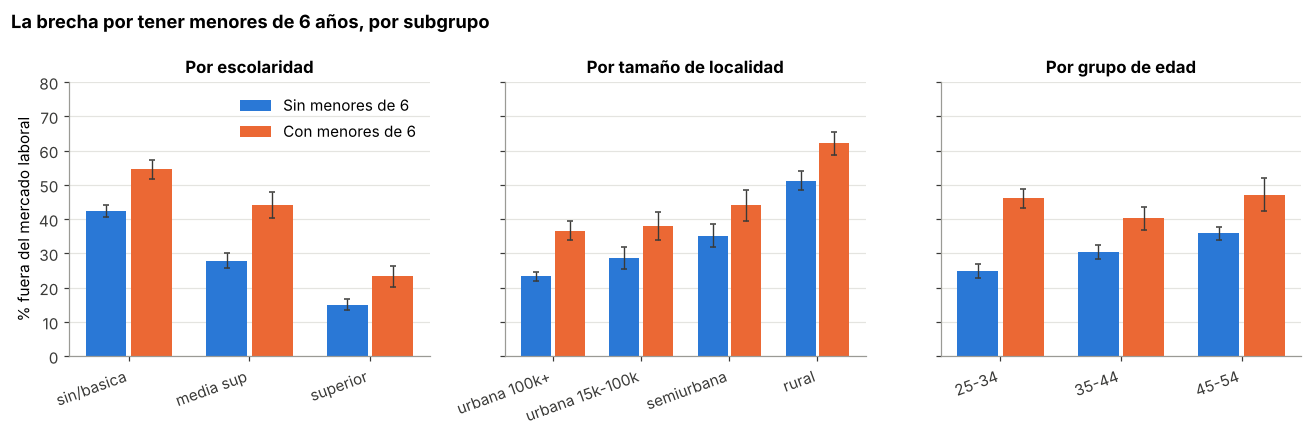

In [12]:
def limpiar(etq):
    # "1 urbana 100k+" -> "urbana 100k+" (el número solo sirve para ordenar)
    return etq.split(" ", 1)[1] if len(etq) > 2 and etq[0].isdigit() and etq[1] == " " else etq

def panel(ax, var, titulo):
    t = base.groupby([var, "hay_0a5"], observed=True).apply(prop_ic, include_groups=False).reset_index()
    orden = sorted(t[var].unique())
    x = np.arange(len(orden)); ancho = 0.38
    for k, (h, etiqueta) in enumerate([(0, "Sin menores de 6"), (1, "Con menores de 6")]):
        d = t[t["hay_0a5"] == h].set_index(var).reindex(orden)
        xs = x + (k - 0.5) * ancho
        ax.bar(xs, d["pct"], ancho - 0.04, color=COL["sin" if h == 0 else "con"], label=etiqueta)
        ax.errorbar(xs, d["pct"], yerr=[d["pct"] - d["ic_inf"], d["ic_sup"] - d["pct"]],
                    fmt="none", ecolor=COL["tinta"], lw=0.9, capsize=2)
    ax.set_xticks(x, [limpiar(o) for o in orden], rotation=20, ha="right")
    ax.set_title(titulo); ax.set_ylim(0, 80)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
panel(axes[0], "escolaridad", "Por escolaridad")
panel(axes[1], "localidad", "Por tamaño de localidad")
panel(axes[2], "grupo_edad", "Por grupo de edad")
axes[0].set_ylabel("% fuera del mercado laboral")
axes[0].legend(frameon=False, loc="upper right")
fig.suptitle("La brecha por tener menores de 6 años, por subgrupo", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

### 6.1 Por qué las horas de cuidado **no** entran como variable explicativa
Es tentador modelar "más horas de cuidado → más probabilidad de estar fuera del mercado". El problema es la **causalidad inversa**: quien no tiene empleo remunerado tiene más horas disponibles y termina cuidando más. Las horas de cuidado son en parte *consecuencia* de estar fuera del mercado, no solo causa.

Por eso el modelo usa la **demanda de cuidados del hogar** (cuántos menores hay, cuántas personas necesitan cuidados), que no depende de la decisión laboral de la mujer. Las horas se reportan solo como descripción:

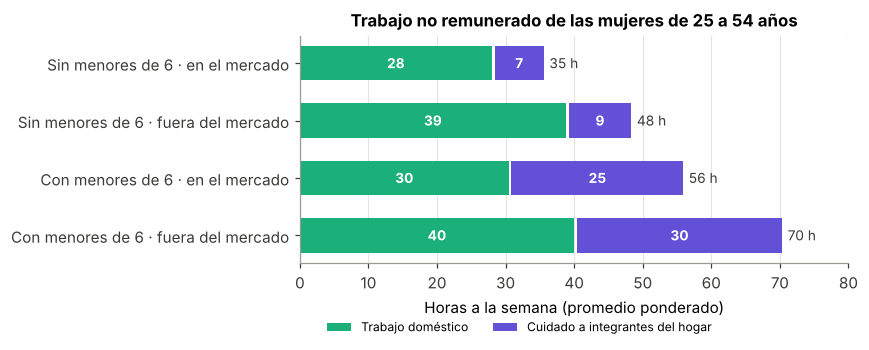

In [13]:
horas = (base.groupby(["hay_0a5", "fuera_mercado"])
             .apply(lambda g: pd.Series({
                 "domestico": np.average(g["trab_no_rem_hog"], weights=g["fac_per"]),
                 "cuidados": np.average(g["trab_no_rem_cuid_hog"], weights=g["fac_per"]),
             }), include_groups=False).reset_index())
horas["grupo"] = (horas["hay_0a5"].map({0: "Sin menores de 6", 1: "Con menores de 6"}) + " · "
                  + horas["fuera_mercado"].map({0: "en el mercado", 1: "fuera del mercado"}))
horas = horas.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.barh(horas["grupo"], horas["domestico"], color=COL["domestico"], label="Trabajo doméstico", height=0.6)
ax.barh(horas["grupo"], horas["cuidados"], left=horas["domestico"] + 0.4, color=COL["cuidados"], label="Cuidado a integrantes del hogar", height=0.6)
for y, (d, c) in enumerate(zip(horas["domestico"], horas["cuidados"])):
    ax.text(d / 2, y, f"{d:.0f}", va="center", ha="center", color="white", fontsize=9, fontweight="bold")
    ax.text(d + 0.4 + c / 2, y, f"{c:.0f}", va="center", ha="center", color="white", fontsize=9, fontweight="bold")
    ax.text(d + c + 1.2, y, f"{d + c:.0f} h", va="center", color=COL["tinta"], fontsize=9)
ax.set_xlabel("Horas a la semana (promedio ponderado)")
ax.set_title("Trabajo no remunerado de las mujeres de 25 a 54 años")
ax.set_xlim(0, 80)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

Con menores de 6 años en casa, el cuidado se dispara en ambos grupos. Pero las mujeres fuera del mercado acumulan más horas en total. Esa diferencia es en parte *efecto* de no tener empleo, y por eso no la usamos para explicarlo.

## 7. Modelo ingenuo: regresión logística

Ajustamos el mismo modelo de tres maneras para ver qué cambia:

| Versión | Pesos | Errores estándar | ¿Es correcta? |
|---|---|---|---|
| A. Sin pesos | No | Muestreo aleatorio simple | No: describe la muestra, no la población |
| B. Pesos normalizados | Sí (media 1) | Muestreo aleatorio simple | Coeficientes razonables, errores estándar demasiado chicos |
| C. Pesos + conglomerados por UPM | Sí | Robustos por conglomerado (UPM) | Aproximación al diseño. La versión formal va en R (notebook 02) |

El modelo excluye `algun_menor_en_guarderia` a propósito. Que un niño vaya a la guardería también puede ser *consecuencia* de que la madre trabaje, así que tiene el mismo problema de causalidad inversa.

In [14]:
formula = ("fuera_mercado ~ hay_0a5 + n_6a14 + n_60mas + n_req_cuidado"
           " + C(grupo_edad) + C(escolaridad) + C(rol_hogar) + C(localidad)")
dm = base.dropna(subset=["escolaridad", "grupo_edad"]).copy()
dm["w_norm"] = dm["fac_per"] / dm["fac_per"].mean()

mA = smf.glm(formula, data=dm, family=sm.families.Binomial()).fit()
mB = smf.glm(formula, data=dm, family=sm.families.Binomial(), freq_weights=dm["w_norm"]).fit()
mC = smf.glm(formula, data=dm, family=sm.families.Binomial(), var_weights=dm["w_norm"]).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(dm["upm_dis"])[0]})
print(f"Observaciones: {int(mA.nobs):,}")

Observaciones: 20,203


Nota técnica: los errores estándar de la versión C se verificaron contra un estimador sándwich calculado a mano (puntaje agregado por UPM, con corrección de grados de libertad). Coinciden en todos los coeficientes.

In [15]:
vars_hogar = ["hay_0a5", "n_6a14", "n_60mas", "n_req_cuidado"]
comp = pd.DataFrame({
    "OR (B, ponderado)": np.exp(mB.params[vars_hogar]),
    "coef A sin pesos": mA.params[vars_hogar],
    "coef B ponderado": mB.params[vars_hogar],
    "EE B (MAS)": mB.bse[vars_hogar],
    "EE C (conglom.)": mC.bse[vars_hogar],
})
comp["EE C / EE B"] = comp["EE C (conglom.)"] / comp["EE B (MAS)"]
comp["p B"] = mB.pvalues[vars_hogar]
comp["p C"] = mC.pvalues[vars_hogar]
comp

,"OR (B, ponderado)",coef A sin pesos,coef B ponderado,EE B (MAS),EE C (conglom.),EE C / EE B,p B,p C
hay_0a5,1.624,0.501,0.485,0.037,0.050,1.378,0.000,0.000
n_6a14,1.079,0.083,0.076,0.018,0.024,1.301,0.000,0.002
n_60mas,1.040,0.032,0.039,0.035,0.050,1.441,0.256,0.430
n_req_cuidado,1.045,0.061,0.044,0.034,0.043,1.275,0.192,0.306


**Cómo leer la tabla**

- **OR (razón de momios):** tener al menos un niño de 0 a 5 años multiplica los momios de estar fuera del mercado por ese factor, manteniendo constante lo demás.
- **Columna A frente a B:** cuánto cambian los coeficientes por usar o no el factor de expansión.
- **EE C / EE B:** si es mayor que 1, el modelo ingenuo **subestima** la incertidumbre. Es el efecto de diseño por conglomerados: personas de la misma UPM se parecen entre sí, así que aportan menos información independiente de la que el modelo supone.

In [16]:
print(mC.summary().tables[1])

                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -0.3413      0.071     -4.831      0.000      -0.480      -0.203
C(grupo_edad)[T.35-44]               -0.1350      0.057     -2.387      0.017      -0.246      -0.024
C(grupo_edad)[T.45-54]                0.0860      0.062      1.384      0.166      -0.036       0.208
C(escolaridad)[T.2 media sup]        -0.3977      0.055     -7.292      0.000      -0.505      -0.291
C(escolaridad)[T.3 superior]         -1.1218      0.064    -17.565      0.000      -1.247      -0.997
C(rol_hogar)[T.jefa]                 -0.7502      0.056    -13.335      0.000      -0.860      -0.640
C(rol_hogar)[T.otro]                 -0.6586      0.069     -9.479      0.000      -0.795      -0.522
C(localidad)[T.2 urbana 15k-100k]     0.0526      0.073      0.725      0.469     

### 7.1 Razones de momios del modelo C
Cada punto es una razón de momios con su IC 95%. A la derecha de la línea punteada: se asocia con **mayor** probabilidad de estar fuera del mercado. A la izquierda: con **menor**. Si el intervalo cruza la línea, no se distingue de "sin asociación".

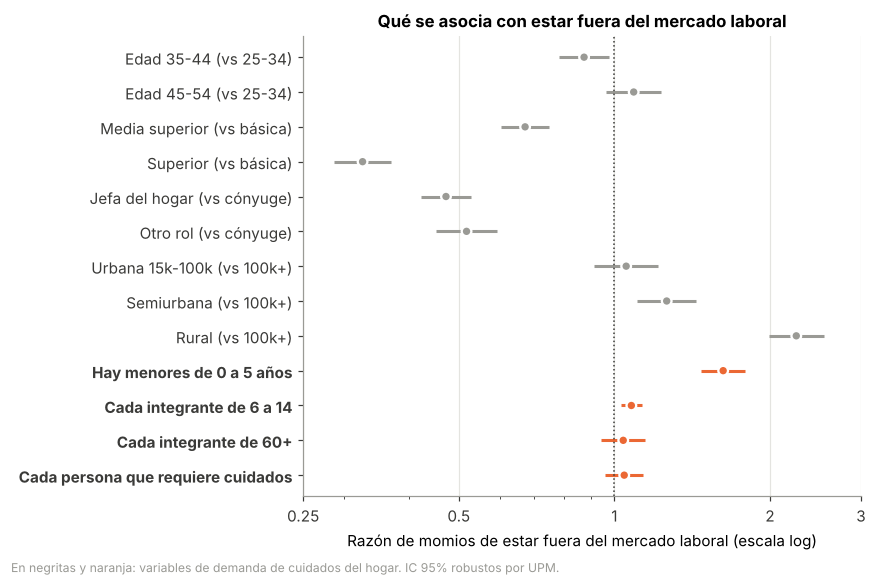

In [17]:
ETIQ = {
    "hay_0a5": "Hay menores de 0 a 5 años", "n_6a14": "Cada integrante de 6 a 14", "n_60mas": "Cada integrante de 60+",
    "n_req_cuidado": "Cada persona que requiere cuidados",
    "C(grupo_edad)[T.35-44]": "Edad 35-44 (vs 25-34)", "C(grupo_edad)[T.45-54]": "Edad 45-54 (vs 25-34)",
    "C(escolaridad)[T.2 media sup]": "Media superior (vs básica)", "C(escolaridad)[T.3 superior]": "Superior (vs básica)",
    "C(rol_hogar)[T.jefa]": "Jefa del hogar (vs cónyuge)", "C(rol_hogar)[T.otro]": "Otro rol (vs cónyuge)",
    "C(localidad)[T.2 urbana 15k-100k]": "Urbana 15k-100k (vs 100k+)", "C(localidad)[T.3 semiurbana]": "Semiurbana (vs 100k+)",
    "C(localidad)[T.4 rural]": "Rural (vs 100k+)",
}
ic = np.exp(mC.conf_int()); ic.columns = ["inf", "sup"]
orx = pd.DataFrame({"OR": np.exp(mC.params)}).join(ic).drop("Intercept")
orx["etiqueta"] = orx.index.map(ETIQ)
orx["hogar"] = orx.index.isin(vars_hogar)
orx = orx.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
y = np.arange(len(orx))
color = np.where(orx["hogar"], COL["con"], COL["gris"])
ax.hlines(y, orx["inf"], orx["sup"], color=color, lw=2)
ax.scatter(orx["OR"], y, color=color, s=40, zorder=3, edgecolor="white", linewidth=1.5)
ax.axvline(1, color=COL["tinta"], ls=":", lw=1)
ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2, 3], ["0.25", "0.5", "1", "2", "3"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, orx["etiqueta"])
for t in ax.get_yticklabels():
    if t.get_text() in [ETIQ[v] for v in vars_hogar]:
        t.set_fontweight("bold")
ax.set_xlabel("Razón de momios de estar fuera del mercado laboral (escala log)")
ax.set_title("Qué se asocia con estar fuera del mercado laboral")
fig.text(0.01, -0.01, "En negritas y naranja: variables de demanda de cuidados del hogar. IC 95% robustos por UPM.", fontsize=8, color=COL["gris"])
plt.tight_layout(); plt.show()

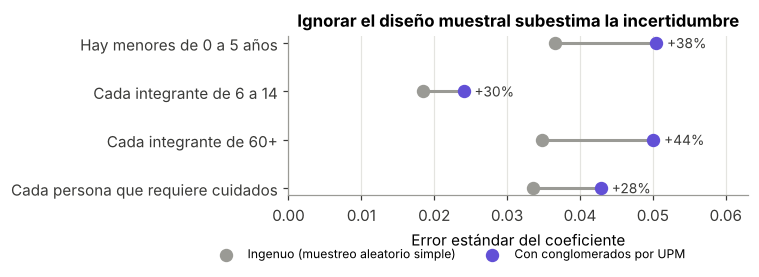

In [18]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
y = np.arange(len(vars_hogar))[::-1]
ax.hlines(y, comp["EE B (MAS)"], comp["EE C (conglom.)"], color=COL["gris"], lw=2)
ax.scatter(comp["EE B (MAS)"], y, color=COL["gris"], s=60, zorder=3, label="Ingenuo (muestreo aleatorio simple)")
ax.scatter(comp["EE C (conglom.)"], y, color=COL["cuidados"], s=60, zorder=3, label="Con conglomerados por UPM")
for yi, (c, r) in zip(y, zip(comp["EE C (conglom.)"], comp["EE C / EE B"])):
    ax.text(c + 0.0015, yi, f"+{(r - 1) * 100:.0f}%", va="center", color=COL["tinta"], fontsize=9)
ax.set_yticks(y, [ETIQ[v] for v in vars_hogar])
ax.set_xlabel("Error estándar del coeficiente")
ax.set_xlim(0, comp["EE C (conglom.)"].max() * 1.25)
ax.set_title("Ignorar el diseño muestral subestima la incertidumbre")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.35, -0.25), ncol=2)
plt.tight_layout(); plt.show()

## 8. Heterogeneidad: ¿la asociación depende de la escolaridad?
Las gráficas de la sección 6.1 sugieren que la brecha cambia según la escolaridad. Lo probamos con una **interacción** `hay_0a5 × escolaridad`. Si la interacción es significativa, el programa debería focalizarse por nivel educativo y no solo por la presencia de menores.

In [19]:
f_int = formula.replace("hay_0a5 +", "hay_0a5 * C(escolaridad) +", 1)
mI = smf.glm(f_int, data=dm, family=sm.families.Binomial(), var_weights=dm["w_norm"]).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(dm["upm_dis"])[0]})
terminos = [t for t in mI.params.index if t.startswith("hay_0a5:")]
prueba = mI.wald_test(", ".join(f"{t} = 0" for t in terminos), scalar=True)
print(f"Prueba de Wald conjunta de la interacción: chi2 = {prueba.statistic:.2f}, gl = {len(terminos)}, p = {prueba.pvalue:.4f}")

Prueba de Wald conjunta de la interacción: chi2 = 4.27, gl = 2, p = 0.1183


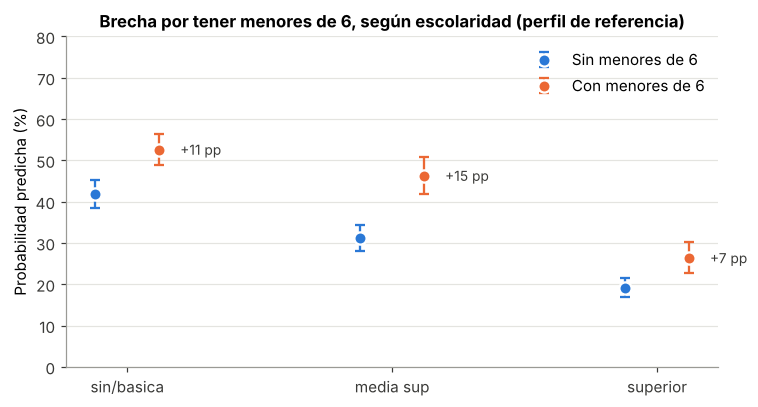

In [20]:
# Probabilidad predicha para un perfil de referencia: cónyuge, 25-34 años, ciudad de 100k+,
# sin otros integrantes dependientes. Solo cambian escolaridad y presencia de menores de 6.
perfil = pd.DataFrame([
    {"escolaridad": e, "hay_0a5": h, "n_6a14": 0, "n_60mas": 0, "n_req_cuidado": 0,
     "grupo_edad": "25-34", "rol_hogar": "conyuge", "localidad": "1 urbana 100k+"}
    for e in sorted(dm["escolaridad"].unique()) for h in (0, 1)])
pred = mI.get_prediction(perfil).summary_frame()
perfil[["p", "inf", "sup"]] = pred[["mean", "mean_ci_lower", "mean_ci_upper"]].to_numpy() * 100

fig, ax = plt.subplots(figsize=(7, 3.8))
niveles = sorted(perfil["escolaridad"].unique()); x = np.arange(len(niveles))
for h, desp in [(0, -0.12), (1, 0.12)]:
    d = perfil[perfil["hay_0a5"] == h].set_index("escolaridad").reindex(niveles)
    c = COL["sin" if h == 0 else "con"]
    ax.errorbar(x + desp, d["p"], yerr=[d["p"] - d["inf"], d["sup"] - d["p"]], fmt="o", color=c, ms=8,
                capsize=3, lw=1.5, mec="white", mew=1.5, label="Con menores de 6" if h else "Sin menores de 6")
for i, n in enumerate(niveles):
    d = perfil[perfil["escolaridad"] == n].set_index("hay_0a5")["p"]
    ax.annotate(f"+{d[1] - d[0]:.0f} pp", (i + 0.2, d[1]), va="center", fontsize=9, color=COL["tinta"])
ax.set_xticks(x, [limpiar(n) for n in niveles])
ax.set_ylabel("Probabilidad predicha (%)"); ax.set_ylim(0, 80)
ax.set_title("Brecha por tener menores de 6, según escolaridad (perfil de referencia)")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

**Cómo leerlo.** "pp" son puntos porcentuales de diferencia entre tener y no tener menores de 6 años, para una mujer con el perfil de referencia. Las probabilidades dependen del perfil elegido; lo que importa es **cómo cambia la brecha** entre niveles educativos y si la prueba de Wald la respalda.

## 9. Validación del modelo
Este modelo es **explicativo**: lo usamos para entender asociaciones, no para predecir casos individuales. Aun así hay que revisar que sus probabilidades estén **calibradas**. Si dice 40%, en ese grupo debería estar fuera del mercado alrededor del 40%.

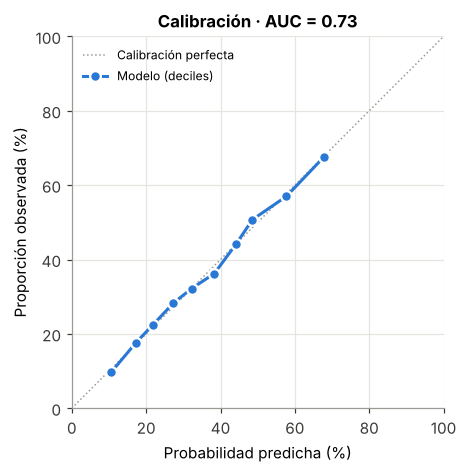

In [21]:
from scipy.stats import rankdata

dm["p_hat"] = mC.predict(dm)
dm["decil"] = pd.qcut(dm["p_hat"], 10, labels=False)
cal = dm.groupby("decil").apply(lambda g: pd.Series({
    "predicho": np.average(g["p_hat"], weights=g["fac_per"]) * 100,
    "observado": np.average(g["fuera_mercado"], weights=g["fac_per"]) * 100}), include_groups=False)

# AUC (sin ponderar) con la fórmula de Mann-Whitney
r = rankdata(dm["p_hat"]); n1 = dm["fuera_mercado"].sum(); n0 = len(dm) - n1
auc = (r[dm["fuera_mercado"].to_numpy() == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.grid(axis="x", visible=True)
ax.plot([0, 100], [0, 100], ls=":", color=COL["gris"], lw=1, label="Calibración perfecta")
ax.plot(cal["predicho"], cal["observado"], "-o", color=COL["sin"], lw=2, ms=7, mec="white", mew=1.5, label="Modelo (deciles)")
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.set_aspect("equal")
ax.set_xlabel("Probabilidad predicha (%)"); ax.set_ylabel("Proporción observada (%)")
ax.set_title(f"Calibración · AUC = {auc:.2f}")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

Si los puntos siguen la diagonal, las probabilidades son confiables en promedio. Un AUC alrededor de 0.70 es razonable para un modelo con pocas variables sociodemográficas. Para un modelo explicativo no hace falta más. Si el objetivo fuera predecir casos individuales, aquí empezaría el trabajo de ML (más variables, validación cruzada, otros algoritmos).

## 10. Robustez: ¿la conclusión depende de mis decisiones?
Cada especificación cambia **una** decisión del análisis. Si la razón de momios de `hay_0a5` se mantiene parecida en todas, la conclusión no es un artefacto de cómo definí las cosas.

In [22]:
def or_hay(datos, y="fuera_mercado", ponderado=True):
    datos = datos.copy(); datos["w_norm"] = datos["fac_per"] / datos["fac_per"].mean()
    f = formula.replace("fuera_mercado", y, 1)
    for v in ["localidad", "rol_hogar", "grupo_edad", "escolaridad"]:
        datos[v] = datos[v].astype(str)    # evita categorías vacías heredadas de pd.cut
        if datos[v].nunique() == 1:          # si la submuestra fija una variable, se quita del modelo
            f = f.replace(f" + C({v})", "")
    kw = {"var_weights": datos["w_norm"]} if ponderado else {}
    m = smf.glm(f, data=datos, family=sm.families.Binomial(), **kw).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(datos["upm_dis"])[0]})
    ci = np.exp(m.conf_int().loc["hay_0a5"])
    return pd.Series({"OR": np.exp(m.params["hay_0a5"]), "inf": ci[0], "sup": ci[1], "n": int(m.nobs)})

dm["solo_hogar"] = (dm["cond_aee"] == "5").astype(int)
specs = {
    "Principal (25-54, fuera del mercado)": or_hay(dm),
    "Resultado: se dedica al hogar o cuidados": or_hay(dm, y="solo_hogar"),
    "Población: 25-44 años": or_hay(dm[dm["edad"] <= 44]),
    "Población: solo localidades urbanas 100k+": or_hay(dm[dm["localidad"] == "1 urbana 100k+"]),
    "Población: solo cónyuges": or_hay(dm[dm["rol_hogar"] == "conyuge"]),
    "Sin factor de expansión": or_hay(dm, ponderado=False),
}
rob = pd.DataFrame(specs).T
rob

,OR,inf,sup,n
"Principal (25-54, fuera del mercado)",1.624,1.471,1.792,"20,203.000"
Resultado: se dedica al hogar o cuidados,1.747,1.580,1.933,"20,203.000"
Población: 25-44 años,1.735,1.542,1.951,"14,071.000"
Población: solo localidades urbanas 100k+,1.809,1.552,2.108,"8,790.000"
Población: solo cónyuges,1.546,1.349,1.772,"9,768.000"
Sin factor de expansión,1.650,1.538,1.771,"20,203.000"


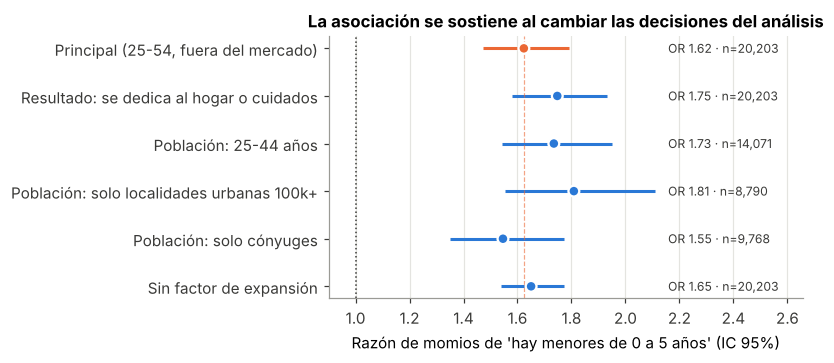

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
r2 = rob.iloc[::-1]; y = np.arange(len(r2))
colores = [COL["con"] if i == len(r2) - 1 else COL["sin"] for i in range(len(r2))]
ax.hlines(y, r2["inf"], r2["sup"], color=colores, lw=2)
ax.scatter(r2["OR"], y, color=colores, s=50, zorder=3, edgecolor="white", linewidth=1.5)
ax.axvline(1, color=COL["tinta"], ls=":", lw=1)
ax.axvline(rob.iloc[0]["OR"], color=COL["con"], ls="--", lw=0.8, alpha=0.6)
for yi, (o, n) in zip(y, zip(r2["OR"], r2["n"])):
    ax.text(r2["sup"].max() + 0.05, yi, f"OR {o:.2f} · n={n:,.0f}", va="center", fontsize=8, color=COL["tinta"])
ax.set_yticks(y, r2.index)
ax.set_xlim(0.9, r2["sup"].max() + 0.55)
ax.set_xlabel("Razón de momios de 'hay menores de 0 a 5 años' (IC 95%)")
ax.set_title("La asociación se sostiene al cambiar las decisiones del análisis")
plt.tight_layout(); plt.show()

## 11. Exportar la base para el notebook 02 (R)

In [24]:
cols = ["id_persona", "llavehog", "est_dis", "upm_dis", "fac_per", "en_dominio", "fuera_mercado",
        "hay_0a5", "n_0a5", "n_6a14", "n_60mas", "n_req_cuidado", "algun_menor_en_guarderia",
        "grupo_edad", "escolaridad", "rol_hogar", "localidad", "edad", "horas_cuidado", "cve_ent"]
salida = PROCESSED / "enut2024_personas_12mas.csv"
todas[cols].to_csv(salida, index=False)
print(f"Guardado: {salida.relative_to(RAIZ)} ({len(todas):,} filas; {todas['en_dominio'].sum():,} en el dominio)")

Guardado: data/processed/enut2024_personas_12mas.csv (74,053 filas; 20,203 en el dominio)


## 12. Conclusiones y siguientes pasos

1. **Calidad de datos:** las llaves de persona del CSV oficial vienen corruptas por notación científica. Se reconstruyeron con `llavehog + n_ren` y se verificó que son únicas y consistentes entre tablas.
2. **Asociación principal:** tener al menos un niño o niña de 0 a 5 años en el hogar se asocia con momios alrededor de **1.6 veces** mayores de estar fuera del mercado laboral, controlando por edad, escolaridad, rol en el hogar y tamaño de localidad. En términos descriptivos: 31% sin menores de 6, 43% con uno, 49% con dos o más.
3. **Robustez:** la razón de momios se mantiene entre 1.55 y 1.81 al cambiar la definición del resultado, la población y el uso de pesos. La conclusión no depende de una decisión arbitraria.
4. **Heterogeneidad, no confirmada:** la brecha parece mayor en media superior (+15 pp) que en educación superior (+7 pp), pero la prueba de la interacción no es significativa (p ≈ 0.12). Con estos datos **no** se puede afirmar que el programa deba focalizarse por escolaridad. Decirlo así es más honesto que vender un hallazgo que la prueba no respalda.
5. **Lo que no salió:** la cantidad de adultos mayores y de personas que requieren cuidados no muestra una asociación distinguible de cero. Puede ser un hallazgo real o un problema de medición. Merece revisión antes de descartarlo.
6. **Calidad del modelo:** las probabilidades están bien calibradas (los deciles siguen la diagonal) y el AUC es 0.73, razonable para un modelo explicativo con variables sociodemográficas.
7. **Incertidumbre:** al considerar los conglomerados, los errores estándar crecen entre 28% y 44%. El modelo ingenuo es demasiado optimista.
8. **Límites:** son asociaciones, no efectos causales. La ENUT es representativa a nivel nacional y por dominios; no la uses para conclusiones por municipio.

**Siguiente:** `02_modelo_diseno_muestral.qmd`, el mismo modelo en R con `survey::svyglm`, que además incorpora los estratos (`est_dis`).